# Cenários de negócio: o que muda se as janelas forem mais flexíveis?

Este notebook examina resultados congelados em `outputs/frozen/window_scenarios/` e `outputs/frozen/early_delivery/` para medir quanto uma política de janelas flexíveis economiza em veículos, distância e duração das rotas, bem como o custo de reorganização do plano, sem acionar nenhum solver durante a leitura. A seção 7 acrescenta os resultados do experimento B5 (`outputs/frozen/v2/B5_windows/` e `outputs/frozen/v2/B5_early/`), no qual ambos os cenários foram repetidos com partida a quente entre níveis consecutivos.

Mantendo a separação estrita definida em `reports/pre-analise-proposta.md` (seção 2), enquanto a camada A (notebooks 03 a 05) resolve o VRPTW rígido de Solomon frente ao SINTEF, a camada B modifica as restrições do problema e, por isso, exclui qualquer comparação com o SINTEF. Cada cenário é contrastado apenas com o respectivo plano-base da mesma instância sem alteração (fator 1,0 ou tolerância 0), resolvido pelo mesmo solver congelado em 30 s (Barr et al., 1995) sobre as 14 instâncias de desenvolvimento.

Na convenção de Solomon (Solomon, 1987; Toth & Vigo, 2014), veículos que chegam antes da abertura esperam até o início da janela, ao passo que operações reais frequentemente aceitam entregas antecipadas. O cenário de entrega antecipada modela essa flexibilização antecipando a abertura das janelas em 25%, 50% ou 100% de sua largura, ou eliminando-a por completo (tolerância livre até o fim da janela), mantendo fixo o fechamento; já o cenário de janelas alargadas expande simetricamente abertura e fechamento pelos fatores 1,25, 1,5 e 2,0. Apenas os dados de entrada são transformados, e o OR-Tools (Perron & Furnon, 2026) segue minimizando frota e distância (Bräysy & Gendreau, 2005a), tratando eventuais reduções de duração como subproduto. Os parâmetros lidos de `config/experiment.toml` são detalhados na seção 1.

## 1. Preparação do ambiente

Carregam-se as 14 instâncias de desenvolvimento, os registros congelados dos dois cenários e os parâmetros efetivos de `config/experiment.toml`. As tabelas exibem os parâmetros aplicados e auditam completude, factibilidade diante das instâncias transformadas e isolamento do conjunto `dev`.

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import (
    benchmark,
    business,
    config,
    eda,
    paths,
    results,
    route_compare,
    v2_view,
    viz_business,
    viz_results,
)
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
cfg = config.load_config()
instances = results.load_dev_inputs(P["sintef_zip"], split)
window = results.load_window_scenarios(R["window_scenarios"], split)
early = results.load_early_delivery(R["early_delivery"], split)

display(eda.localize_columns(business.config_table(cfg, LANG), LANG))
display(eda.localize_columns(business.run_checks(window, early, split, LANG), LANG))

,Indicador,Valor
0,Estratégia de frota (congelada),fixed_cost
1,Solução inicial (congelada),SAVINGS
2,Metaheurística (congelada),GUIDED_LOCAL_SEARCH
3,Janelas: fatores de largura,"1, 1.25, 1.5, 2"
4,Janelas: modo de alargamento,symmetric
5,Janelas: orçamento (s),30
6,Janelas: conjunto de instâncias,dev
7,Entrega antecipada: tolerâncias (fração da lar...,"0, 0.25, 0.5, 1, full"
8,Entrega antecipada: réplicas,3
9,Entrega antecipada: orçamento (s),30


,Indicador,Valor
0,Janelas alargadas: células,56
1,Janelas alargadas: factíveis no verificador,56 / 56
2,Entrega antecipada: células,210
3,Entrega antecipada: factíveis no verificador,210 / 210
4,Entrega antecipada: réplicas por célula,3
5,Instâncias distintas,14
6,Instâncias fora do conjunto de desenvolvimento,0


### Insight

Os parâmetros conferem com a configuração congelada (`fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH` em 30 s por execução sobre o conjunto `dev`), abrangendo fatores 1, 1,25, 1,5 e 2 no modo simétrico (56 células) e tolerâncias 0, 0,25, 0,5, 1 e livre em 3 réplicas na entrega antecipada (210 células). Todas as células mostram-se factíveis diante das respectivas instâncias transformadas, lembrando que factibilidade sobre dados relaxados implica apenas viabilidade matemática no cenário hipotético, sem validar aceitação comercial pelos clientes nem factibilidade na instância rígida original. A seção 2 avalia o efeito do alargamento simétrico.

## 2. Janelas alargadas

Os quadros e o gráfico comparam os fatores 1,25, 1,5 e 2,0 contra o plano-base de fator 1,0 da mesma instância. Como distâncias de planos com quantidades distintas de veículos medem grandezas incomparáveis, os resultados separam estritamente veículos economizados e variação percentual média da distância por classe de frota (frota igual, reduzida ou maior que a do plano original), além de detalhar os desvios por família.

,Fator de largura,Nº de instâncias,Veículos economizados (média),Instâncias com menos veículos,Instâncias com mais veículos,Instâncias com frota igual
0,1.25×,14,0.29,3,0,11
1,1.5×,14,0.57,7,0,7
2,2×,14,0.79,8,0,6


,Fator de largura,Frota contra o plano-base,Nº de instâncias,Veículos economizados (média),"Variação da distância, média (%)","Variação da distância, mediana (%)"
0,1.25×,frota igual,11,0.00,-4.0,-3.6
1,1.25×,frota reduzida,3,1.33,-6.2,-8.7
2,1.5×,frota igual,7,0.00,-4.4,-0.4
3,1.5×,frota reduzida,7,1.14,-7.2,-9.5
4,2×,frota igual,6,0.00,-2.0,-1.1
5,2×,frota reduzida,8,1.38,-12.3,-11.5


,Família,Nº de instâncias,×1.25 · veículos economizados (média),×1.25 · instâncias com frota igual,"×1.25 · distância, frota igual (%, média)",×1.5 · veículos economizados (média),×1.5 · instâncias com frota igual,"×1.5 · distância, frota igual (%, média)",×2 · veículos economizados (média),×2 · instâncias com frota igual,"×2 · distância, frota igual (%, média)"
0,C1,2,0.00,2,-0.1,0.00,2,-0.1,0.0,2,0.3
1,C2,2,0.00,2,-1.0,0.00,2,-1.0,0.0,2,4.1
2,R1,3,0.33,2,-3.6,0.67,1,-0.4,1.0,1,-2.1
3,R2,3,0.00,3,-4.7,0.67,1,-13.3,1.0,0,NaN
4,RC1,2,1.50,0,NaN,1.50,0,NaN,2.0,0,NaN
5,RC2,2,0.00,2,-10.5,0.50,1,-15.1,0.5,1,-18.9


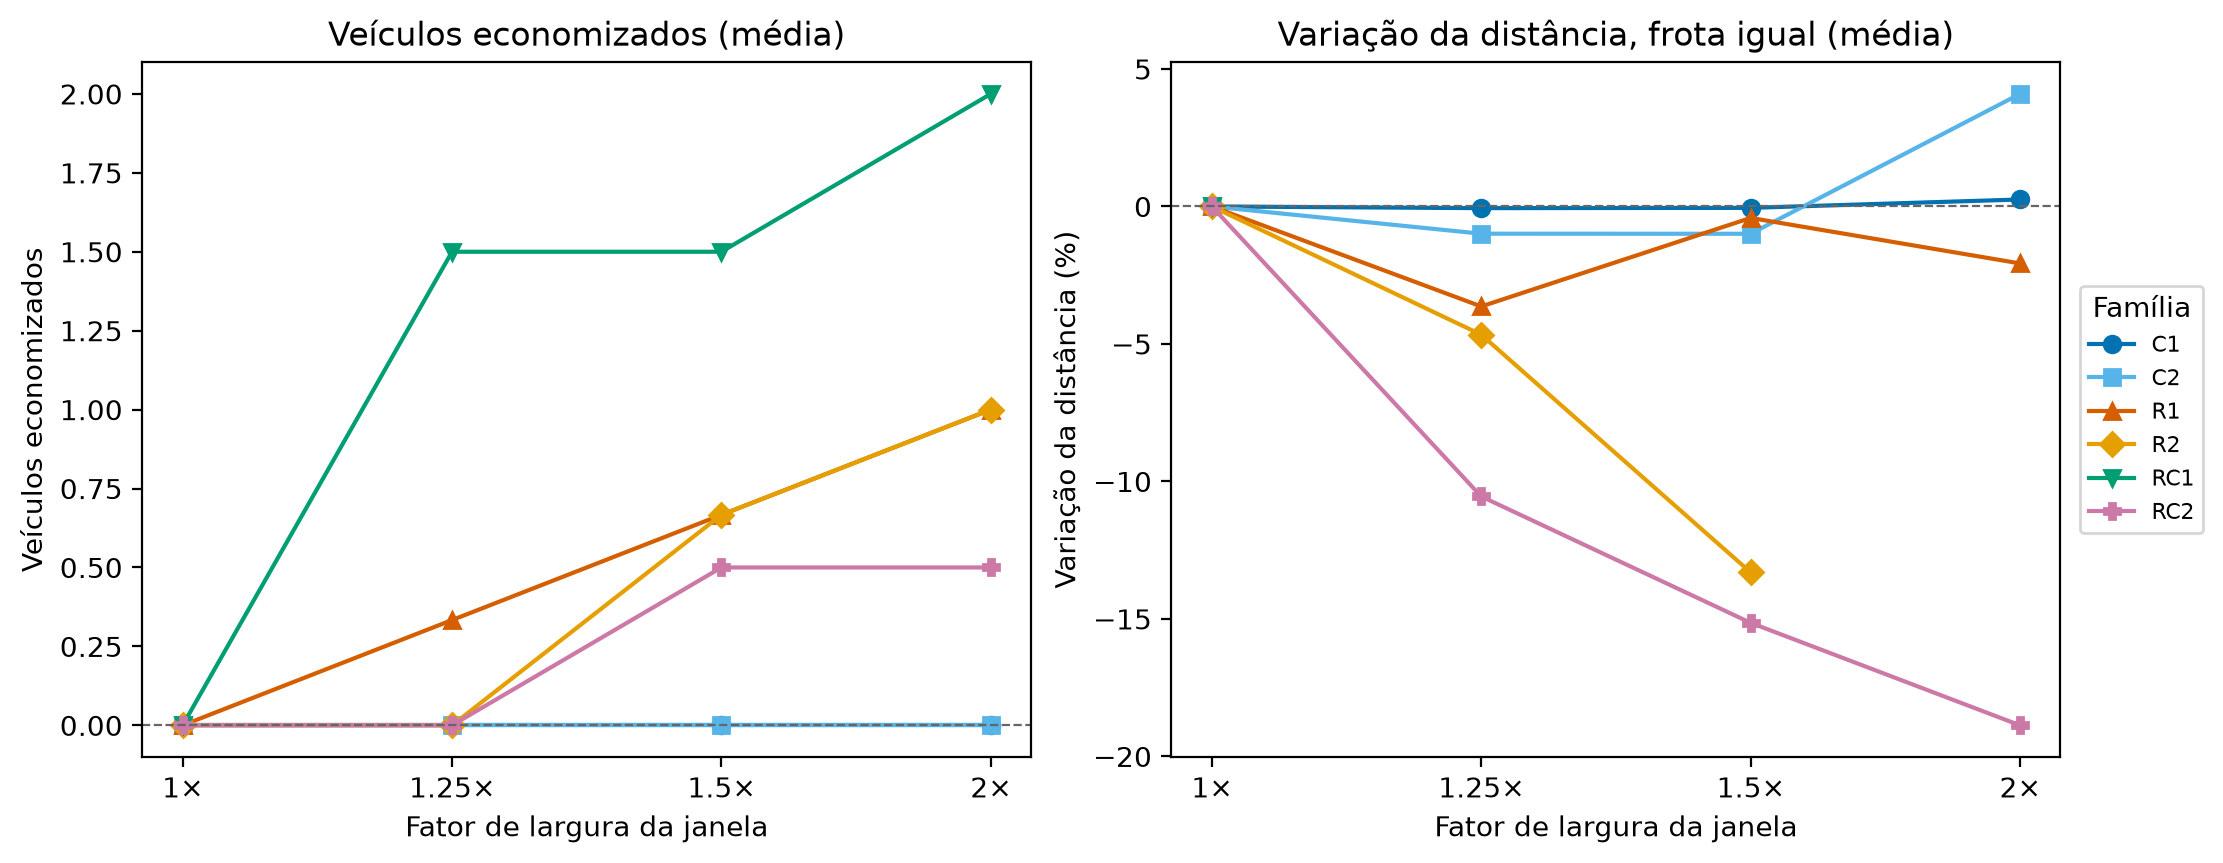

In [2]:
w_sum = business.window_results_summary(window)

display(eda.localize_columns(business.window_by_factor(w_sum), LANG))
display(eda.localize_columns(business.window_distance_by_fleet(w_sum, LANG), LANG))
display(eda.localize_columns(business.window_by_family(w_sum, LANG), LANG))

viz_business.plot_window_effect(w_sum, LANG)
plt.show()

### Insight

Frente ao fator 1,0, o alargamento economizou em média 0,29 veículo no fator 1,25 (redução em 3 de 14 instâncias), 0,57 no fator 1,5 (7 de 14) e 0,79 no fator 2,0 (8 de 14), sem nenhuma instância exigir veículos extras. Nas instâncias que mantiveram a mesma frota, a distância média variou −4,0% (11 instâncias em 1,25), −4,4% (7 em 1,5) e −2,0% (6 em 2,0), com medianas de −3,6%, −0,4% e −1,1%; nas que reduziram a frota, variou −6,2% (3 instâncias economizando 1,33 veículo em média), −7,2% (7 economizando 1,14) e −12,3% (8 economizando 1,38), com medianas de −8,7%, −9,5% e −11,5%.

Por família, C1 e C2 mantiveram economia nula de frota em todos os fatores e oscilações discretas de distância (−1,0% a +4,1% em apenas 2 instâncias por célula), coerente com a restrição ativa de capacidade identificada no notebook 02. Em contrapartida, R1 economizou 0,33, 0,67 e 1,00 veículo; R2 economizou 0,00, 0,67 e 1,00; RC1 economizou 1,50, 1,50 e 2,00; e RC2 economizou 0,00, 0,50 e 0,50, restando poucos casos de frota igual em R e RC. Como os grupos somam apenas 2 ou 3 instâncias em rodada única de 30 s, oscilações de 1 veículo inserem-se na variabilidade por relógio e as médias ilustram tendências sobre instâncias sintéticas. Na seção 3 examina-se a política de entrega antecipada.

## 3. Entrega antecipada

Para avaliar o impacto de entregas antes da abertura da janela, cada nível de tolerância é contrastado com o plano de tolerância 0 da própria instância. Cada célula (instância e tolerância) é representada por um único plano real correspondente à réplica na posição ⌈R/2⌉ da ordenação lexicográfica (infactibilidade, veículos e distância), evitando medianas independentes por coluna que sintetizariam métricas de rotas distintas.

Os resultados são separados por classe de frota e reportam a duração das rotas sob duas convenções de saída lado a lado: saída simultânea no instante zero e saída ótima ajustada pela folga temporal (Savelsbergh, 1992). Na saída em zero, veículos que chegam cedo ao primeiro cliente aguardam sua janela, inflacionando artificialmente a economia aparente quando a antecipação é liberada; a saída ótima desconta essa espera inicial evitável em ambos os planos, e a coluna de inflação quantifica essa diferença em pontos percentuais.

,Antecipação tolerada,Frota contra o plano-base,Nº de instâncias,Veículos economizados (média),Distância (%),"Duração, saída às 0 (%)","Duração, saída ótima (%)",Inflação da saída às 0 (p.p.),Último retorno (%)
0,25%,frota igual,11,0.00,-2.2,-3.0,-2.1,1.0,-0.3
1,25%,frota reduzida,3,1.33,-0.9,-15.3,-9.7,5.6,1.4
2,50%,frota igual,10,0.00,-5.3,-5.1,-3.7,1.3,-1.6
3,50%,frota reduzida,4,1.25,-5.4,-20.0,-13.2,6.8,-0.9
4,100%,frota igual,8,0.00,-7.4,-9.0,-7.3,1.6,-5.3
5,100%,frota reduzida,6,1.17,-6.7,-19.1,-12.1,6.9,-2.6
6,livre,frota igual,7,0.00,-18.1,-25.5,-20.8,4.7,-21.6
7,livre,frota reduzida,6,1.33,-11.0,-19.6,-11.7,7.9,-4.8
8,livre,frota maior,1,-1.00,8.1,0.7,0.7,0.0,0.0


,Família,Antecipação tolerada,Instâncias com frota igual,Instâncias com frota reduzida,Instâncias com frota maior
0,C1,25%,2,0,0
1,C1,50%,2,0,0
2,C1,100%,2,0,0
3,C1,livre,1,0,1
4,C2,25%,2,0,0
5,C2,50%,2,0,0
6,C2,100%,2,0,0
7,C2,livre,2,0,0
8,R1,25%,2,1,0
9,R1,50%,2,1,0


,Família,Indicador,Nº de instâncias,25%,50%,100%,livre
0,C1,"Duração das rotas, saída ótima (%) · frota igual",2,-0.31,-0.18,-0.28,-0.90
1,C2,"Duração das rotas, saída ótima (%) · frota igual",2,0.02,0.02,0.01,0.01
2,R1,"Duração das rotas, saída ótima (%) · frota igual",3,-0.34,-2.43,NaN,NaN
3,R2,"Duração das rotas, saída ótima (%) · frota igual",3,-3.39,-7.63,-13.45,-36.68
4,RC1,"Duração das rotas, saída ótima (%) · frota igual",2,-5.48,-6.81,-6.11,NaN
5,RC2,"Duração das rotas, saída ótima (%) · frota igual",2,-5.72,-10.04,-25.25,-34.79


,Família,Indicador,Nº de instâncias,25%,50%,100%,livre
0,C1,"Duração das rotas, saída às 0 (%) · frota igual",2,-0.82,-0.59,-0.79,-2.17
1,C2,"Duração das rotas, saída às 0 (%) · frota igual",2,0.38,0.47,-0.17,-0.17
2,R1,"Duração das rotas, saída às 0 (%) · frota igual",3,-2.55,-5.88,NaN,NaN
3,R2,"Duração das rotas, saída às 0 (%) · frota igual",3,-4.21,-7.56,-15.45,-43.72
4,RC1,"Duração das rotas, saída às 0 (%) · frota igual",2,-5.76,-10.59,-9.93,NaN
5,RC2,"Duração das rotas, saída às 0 (%) · frota igual",2,-9.14,-13.03,-29.23,-44.75


,Família,Indicador,Nº de instâncias,25%,50%,100%,livre
0,C1,Veículos economizados,2,0.00,0.00,0.00,-0.50
1,C2,Veículos economizados,2,0.00,0.00,0.00,0.00
2,R1,Veículos economizados,3,0.33,0.33,1.00,1.33
3,R2,Veículos economizados,3,0.00,0.33,0.33,0.00
4,RC1,Veículos economizados,2,1.00,1.00,1.00,1.50
5,RC2,Veículos economizados,2,0.50,0.50,0.50,0.50


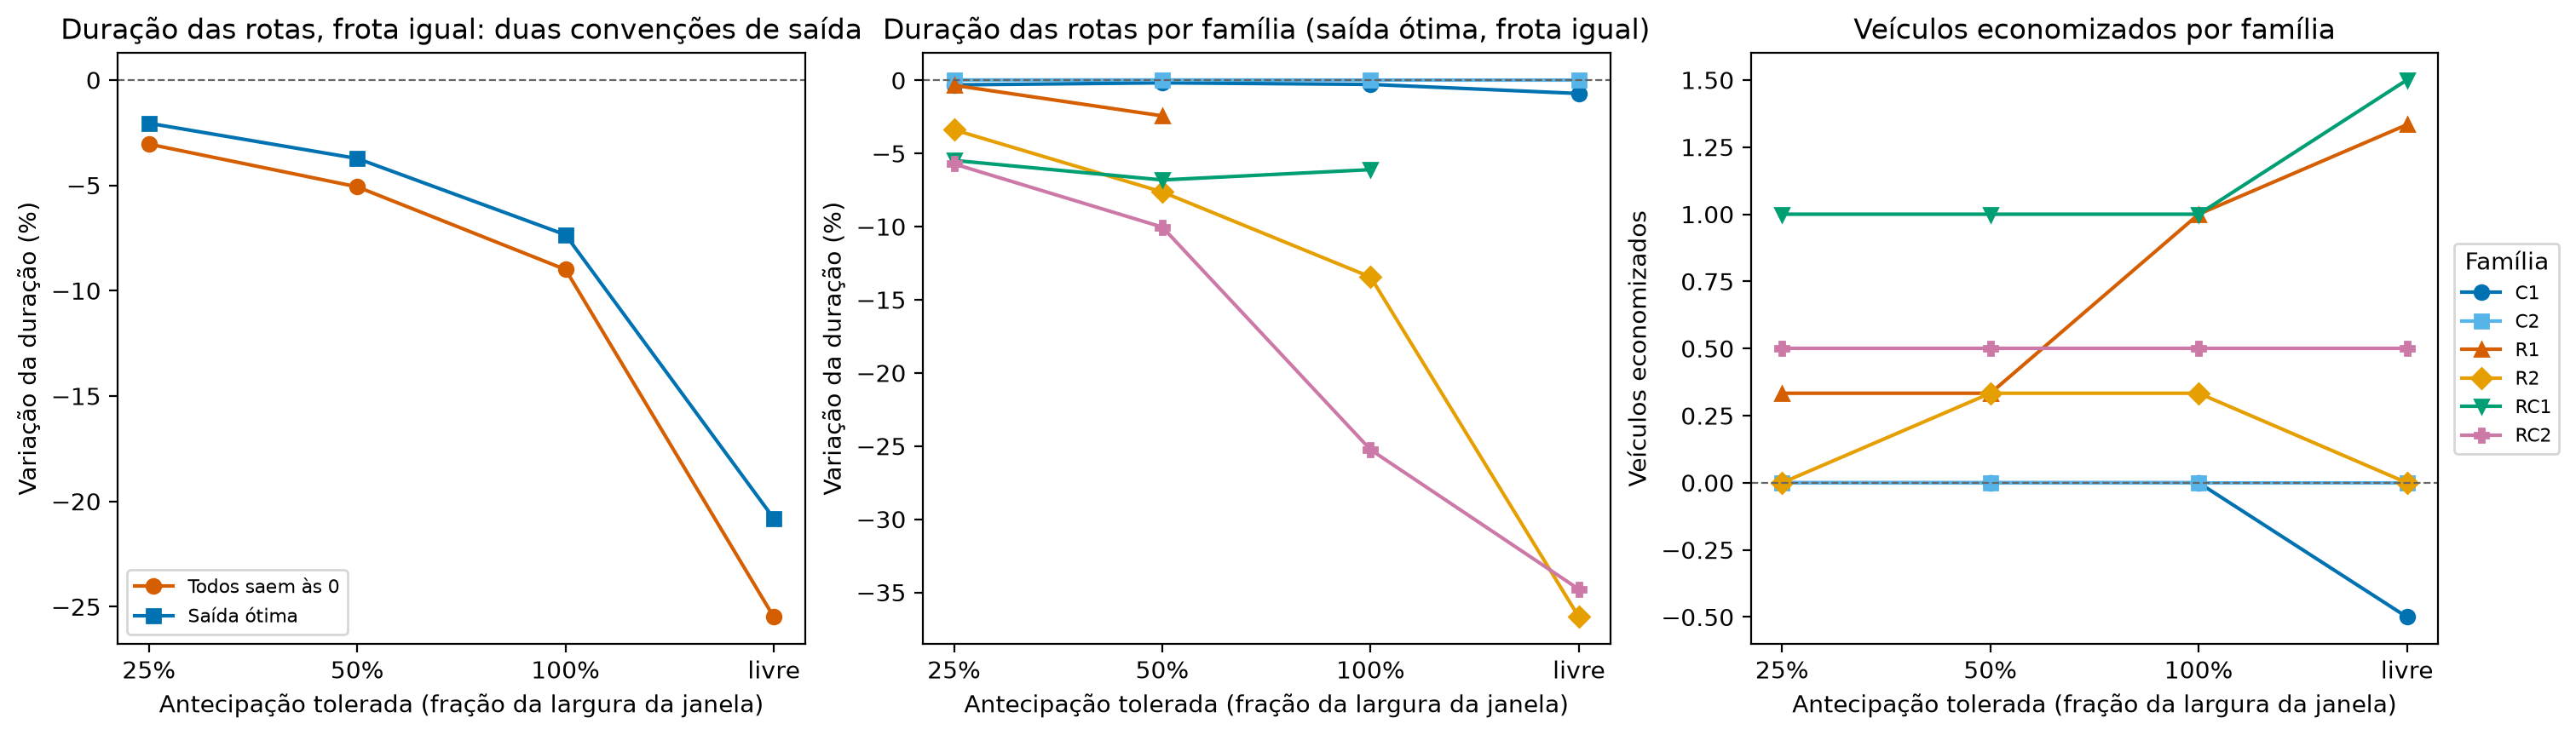

In [3]:
e_sum = business.early_results_summary(early)

display(eda.localize_columns(business.early_by_tolerance(e_sum, LANG), LANG))
display(eda.localize_columns(business.early_fleet_counts(e_sum, LANG), LANG))
display(eda.localize_columns(business.early_by_family(e_sum, "duration_min_pct", LANG, fleet="equal"), LANG))
display(eda.localize_columns(business.early_by_family(e_sum, "duration_pct", LANG, fleet="equal"), LANG))
display(eda.localize_columns(business.early_by_family(e_sum, "vehicles_saved", LANG), LANG))

viz_business.plot_early_effect(e_sum, LANG)
plt.show()

### Insight

Entre as instâncias que conservaram a mesma frota do plano-base (11, 10, 8 e 7 instâncias nos níveis 25%, 50%, 100% e livre), a duração com saída ótima variou −2,1%, −3,7%, −7,3% e −20,8%, e a distância caiu −2,2%, −5,3%, −7,4% e −18,1% (com último retorno ao depósito variando −0,3%, −1,6%, −5,3% e −21,6%). Na convenção com partida às 0, as reduções de duração pareceriam 1,0, 1,3, 1,6 e 4,7 pontos percentuais maiores. Entre as instâncias que reduziram frota (3, 4, 6 e 6 instâncias, economizando de 1,17 a 1,33 veículo), a duração ótima caiu −9,7%, −13,2%, −12,1% e −11,7% (inflacionada em 5,6 a 7,9 pontos na saída em zero) e a distância caiu −0,9%, −5,4%, −6,7% e −11,0%; apenas C106 sob tolerância livre usou 1 veículo a mais (distância +8,1% e duração +0,7%).

Por família sob frota igual e saída ótima na tolerância livre, a duração recuou −36,7% em R2 (3 instâncias) e −34,8% em RC2 (1 instância), contra variações marginais de −0,9% em C1 (1 instância) e +0,0% em C2 (2 instâncias). Todas as instâncias de R1 e RC1 reduziram frota na tolerância livre, acumulando economias médias de 1,33 veículo em R1 e 1,50 em RC1 (contra 0,00 em R2 e 0,50 em RC2). O contraste é compatível com a existência de maior espera ociosa nos horizontes longos da série 2, lembrando que duração é apenas um efeito colateral em amostra pequena de 14 instâncias com 3 réplicas de 30 s. A seção 4 quantifica o quanto as rotas precisam mudar para capturar esses ganhos.

## 4. Realocação das entregas

Cada plano com entrega antecipada é comparado ao plano de tolerância 0 da mesma réplica, contrapondo a reorganização observada ao patamar de ruído (variação natural entre réplicas do próprio plano original). As tabelas reportam medianas percentuais de clientes transferidos de veículo (casamento guloso por maior sobreposição), pares mantidos juntos na mesma rota, concordância global de pares (índice de Rand; Rand, 1971) e arcos preservados, seguidas pelo recorte familiar.

,Antecipação tolerada,Comparações,Clientes realocados (%),Pares mantidos (%),Concordância de pares (%),Trechos mantidos (%)
0,25%,42,43.0,54.2,90.4,39.6
1,50%,42,39.0,48.7,90.8,39.3
2,100%,42,40.5,52.7,90.9,36.1
3,livre,42,33.5,53.4,89.8,25.8
4,ruído,42,0.0,100.0,100.0,100.0


,Família,25%,50%,100%,livre,ruído
0,C1,2.5,2.5,2.5,6.0,0.0
1,C2,0.0,1.0,1.0,1.0,0.0
2,R1,43.0,43.0,43.0,44.0,0.0
3,R2,47.0,57.0,51.0,29.0,0.0
4,RC1,31.0,33.0,36.0,43.0,0.0
5,RC2,61.0,56.0,45.0,51.0,0.0


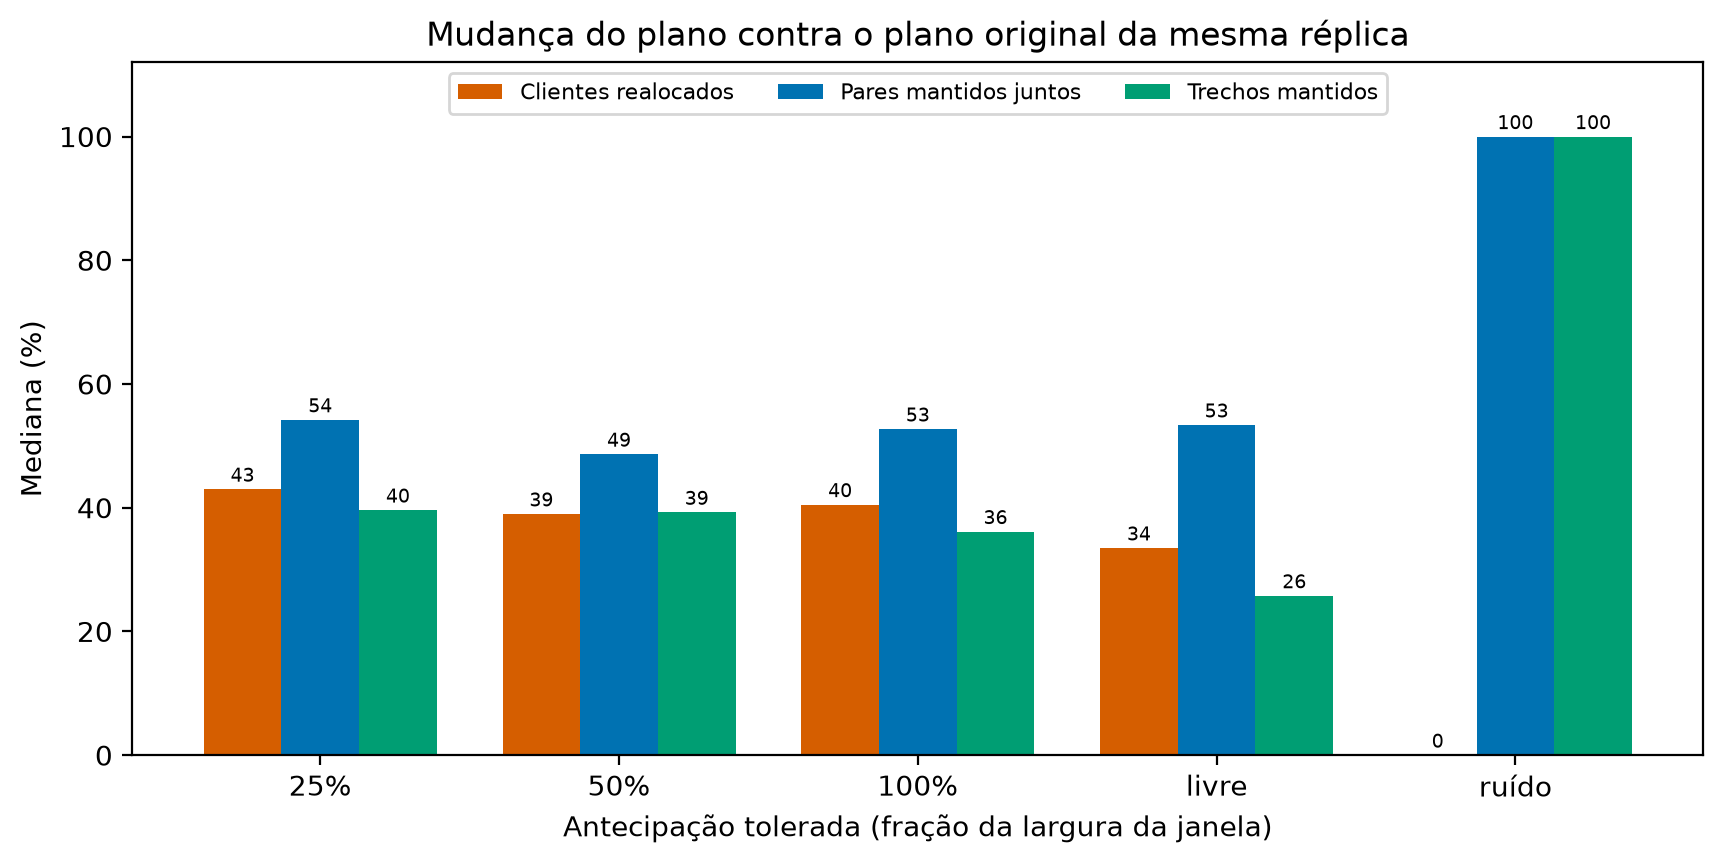

In [4]:
realloc = route_compare.reallocation_table(early)

display(eda.localize_columns(business.reallocation_display(realloc, LANG), LANG))
display(eda.localize_columns(business.reallocation_by_family(realloc, LANG), LANG))

viz_business.plot_reallocation(realloc, LANG)
plt.show()

### Insight

Mesmo a menor tolerância de antecipação (25%) desloca 43,0% dos clientes de veículo em mediana (39,0% em 50%, 40,5% em 100% e 33,5% em livre, contra 0,0% no patamar de ruído), preservando apenas 54,2% a 53,4% dos pares juntos e 39,6% a 25,8% dos arcos (contra 100% no ruído). Isso indica que economias de frota e tempo decorrem de reestruturação ampla dos roteiros, e não de ajustes locais. Nas famílias C, onde a flexibilidade quase não gera economia, a realocação fica restrita a 0,0%–6,0%, ao passo que sobe para 43,0%–44,0% em R1, 29,0%–57,0% em R2, 31,0%–43,0% em RC1 e 45,0%–61,0% em RC2. Embora o ruído medido nesta rodada ociosa tenha sido nulo, oscilações de ±1 veículo ocorrem em máquinas sob carga (seção 6) e o casamento guloso de rotas reflete um critério específico de pareamento. Um exemplo visual concreto ilustra essa mudança na seção 5.

## 5. Exemplo de antes e depois

Entre as instâncias que economizam ao menos 1 veículo na tolerância livre, os mapas ilustram a réplica 1 do caso com maior redução relativa de duração (saída ótima), contrastando o plano original à esquerda com o plano sob entrega livre à direita.

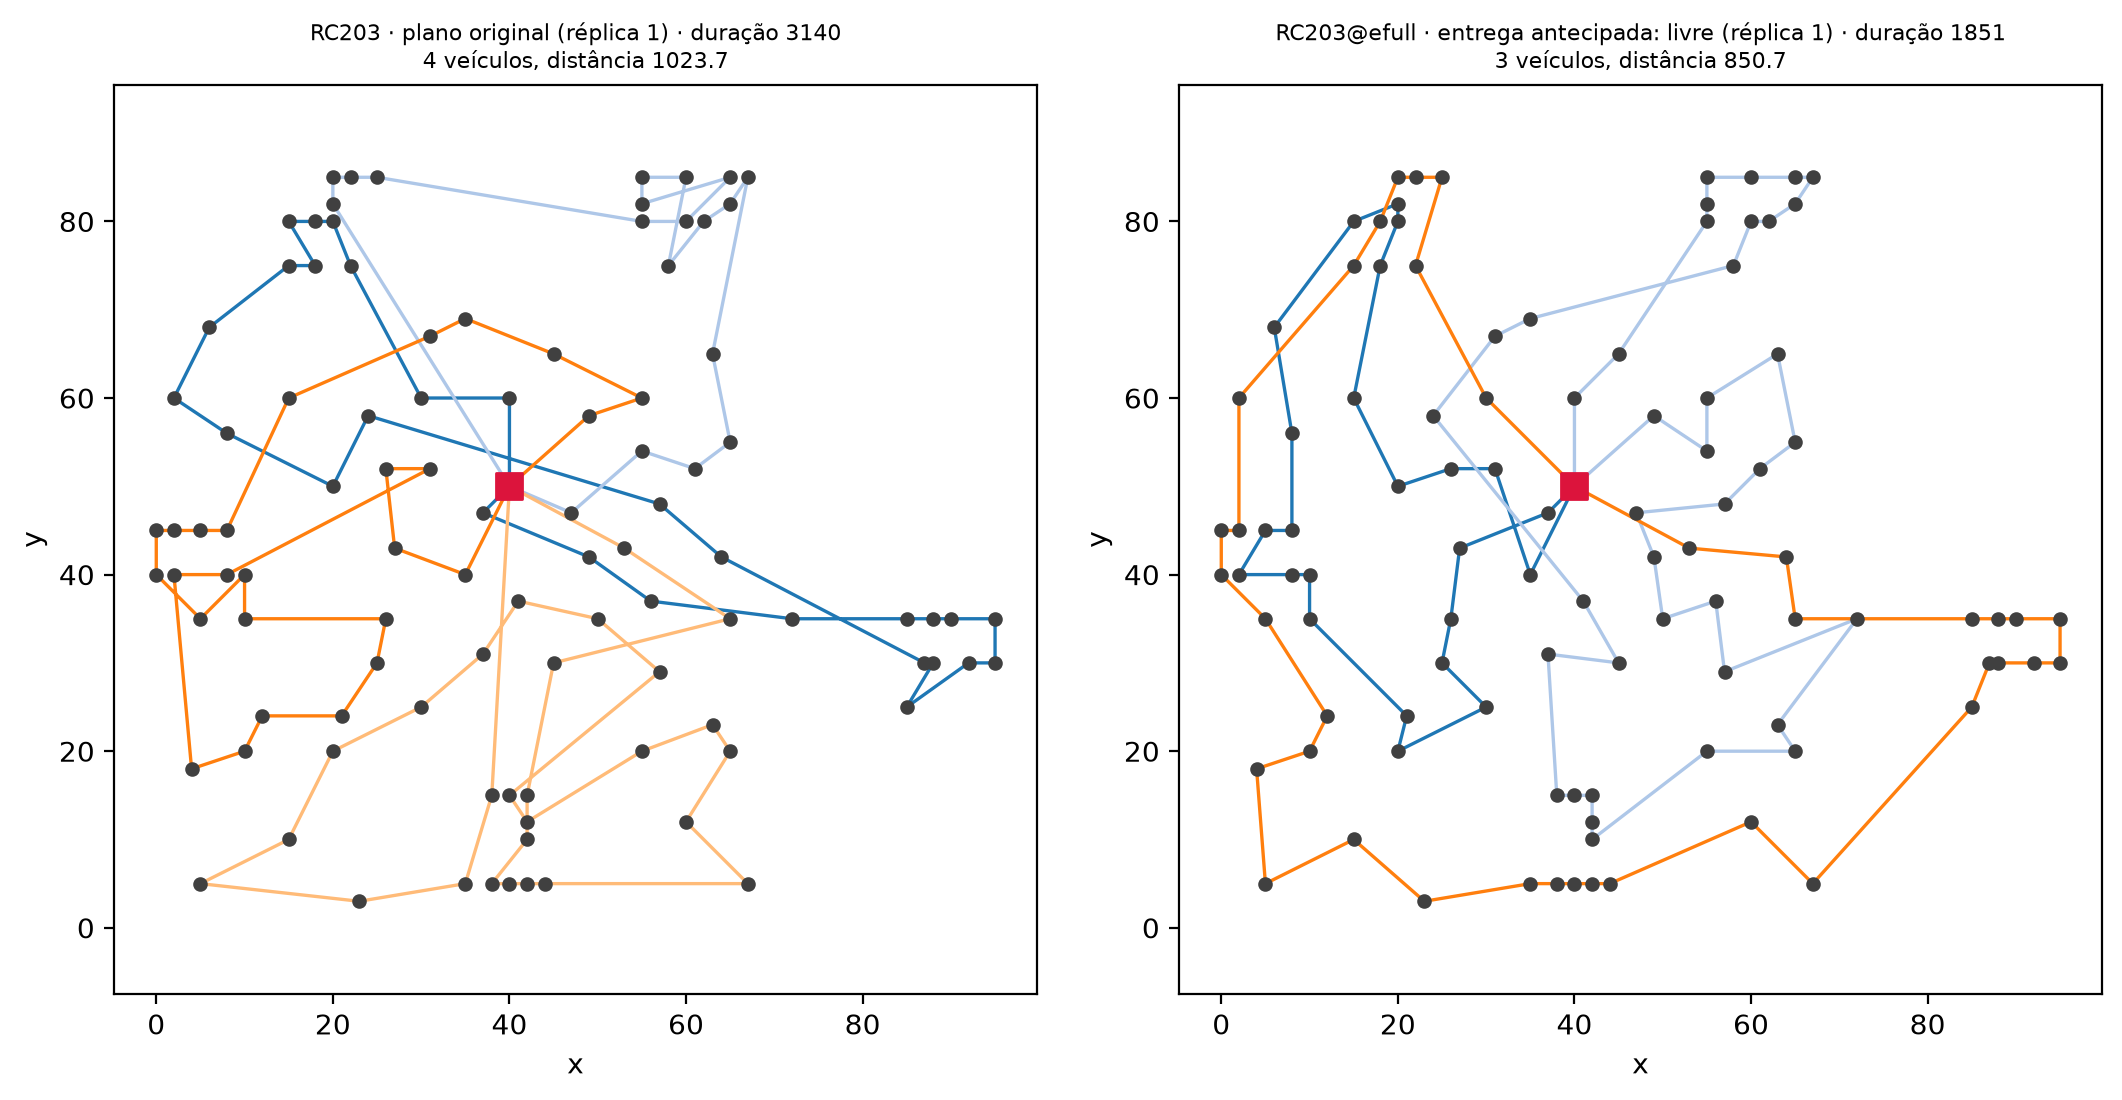

In [5]:
example = business.pick_early_example(e_sum)

viz_results.plot_route_panels(business.before_after_panels(example, instances, early, LANG), LANG)
plt.show()

### Insight

Pelo critério definido, selecionou-se RC203, na qual a réplica 1 (representativa em ambos os níveis e idêntica nas 3 réplicas) passa de 4 veículos, distância 1023,7 e duração de 3140 para 3 veículos, distância 850,7 (−16,9%) e duração de 1851 (−41,1%). Enquanto o plano original exibe sobreposições e cruzamentos entre as quatro rotas, o plano com antecipação livre separa as três rotas por regiões geográficas distintas com completa alteração na composição dos agrupamentos, coerente com a taxa de realocação observada na seção 4. Trata-se de um exemplo escolhido justamente pelo ganho expressivo (em oposição a casos como C106) sobre um subproduto temporal do solver, sem significado escalar nas cores das rotas. A seção 6 quantifica ruído e não monotonicidade nos dados congelados.

## 6. Limitações medidas nos dados

As tabelas extraem diretamente dos registros salvos o ruído interno das réplicas do plano original, a divergência entre uma primeira execução de janelas alargadas realizada sob contenção de máquina e a execução limpa (mantida apenas como evidência da sensibilidade ao relógio) e as células não monotônicas, casos em que um nível mais permissivo atingiu resultado lexicograficamente pior (mais veículos ou, na mesma frota, maior distância) do que o melhor plano de um nível menos permissivo da mesma instância, fenômeno impossível no ótimo exato e atribuível à busca heurística a frio sem partida a quente na v1.

In [6]:
contended = results.load_window_scenarios(R["window_scenarios_contended"], split)

display(eda.localize_columns(business.noise_floor_table(e_sum, realloc, LANG), LANG))
display(eda.localize_columns(business.run_comparison_table(window, contended, LANG), LANG))
display(eda.localize_columns(business.nonmonotonic_cases(w_sum, e_sum, LANG), LANG))

,Indicador,Valor
0,Réplicas do plano original por instância,3
1,Instâncias com frota diferente entre réplicas ...,0 / 14
2,Instâncias com distância diferente entre répli...,1 / 14
3,Clientes realocados entre réplicas do plano or...,0.0


,Indicador,Valor
0,Células comparadas (instância × fator),56
1,Células com frota diferente entre as duas rodadas,4 / 56
2,Maior diferença de frota (veículos),1
3,Células com distância diferente entre as duas ...,22 / 56
4,"Instâncias com frota diferente no fator 1,0",2 / 14


,Cenário,Instância,Nível,Veículos,Distância,Frota do melhor plano em nível menos permissivo,Distância do melhor plano em nível menos permissivo,Piora
0,Janelas alargadas,C103,1.5×,10,858.1,10,857.5,distância (frota igual)
1,Janelas alargadas,C106,1.25×,10,829.4,10,828.9,distância (frota igual)
2,Janelas alargadas,C106,2×,10,859.3,10,828.9,distância (frota igual)
3,Janelas alargadas,C203,2×,3,650.1,3,588.5,distância (frota igual)
4,Janelas alargadas,R108,1.5×,10,966.3,10,962.5,distância (frota igual)
5,Janelas alargadas,RC108,2×,10,1075.9,10,1068.0,distância (frota igual)
6,Entrega antecipada,C103,50%,10,866.5,10,828.1,distância (frota igual)
7,Entrega antecipada,C103,100%,10,866.5,10,828.1,distância (frota igual)
8,Entrega antecipada,C103,livre,10,833.2,10,828.1,distância (frota igual)
9,Entrega antecipada,C106,livre,11,895.9,10,828.9,frota


### Insight

Na entrega antecipada com máquina ociosa, as 3 réplicas do plano base repetiram exatamente a mesma frota nas 14 instâncias e a mesma distância em 13 delas (0,0% de realocação). Já a comparação com a execução anterior sob carga concorrente revelou divergências de frota em 4 de 56 células (até 1 veículo) e de distância em 22 de 56, confirmando que a disputa por CPU eleva o ruído real acima de zero. Sob ordem lexicográfica estrita, emergiram 20 células não monotônicas na v1: 6 em janelas alargadas (todas pioras de distância na mesma frota, chegando a 650,1 contra 588,5 em C203 ×2) e 14 em entrega antecipada (2 pioras de frota sob tolerância livre, C106 de 10 para 11 e R202 de 3 para 4, e 12 pioras de distância). Como as 14 instâncias são sintéticas e não modelam custos contratuais de mudança nem comparação externa com o SINTEF, a seção 7 testa se a partida a quente elimina essa inconsistência.

## 7. Partida a quente entre níveis (B5)

Como o plano obtido em um nível restritivo é matematicamente factível em qualquer relaxamento subsequente, o experimento B5 (`reports/protocolo-v2.md`) reexecutou ambos os cenários nas 14 instâncias de desenvolvimento iniciando cada nível a partir da solução do nível imediatamente anterior (`ReadAssignmentFromRoutes`). Para isolar o efeito da partida a quente, mantiveram-se a configuração v1 e o limite de 30 s por execução (1 réplica nas janelas e 3 na entrega antecipada), com resultados salvos em `outputs/frozen/v2/B5_windows/` e `outputs/frozen/v2/B5_early/`, preservando a ausência de comparação com o SINTEF.

As tabelas e o gráfico verificam a auditoria das execuções, comparam a contagem lexicográfica de células não monotônicas frente à v1 e confrontam a economia de veículos obtida em cada nível pelas duas versões.

,Cenário,Células,Nº de instâncias,Células com partida a quente,Células sem partida (1º nível),Factíveis
0,Janelas alargadas,56,14,42,14,56
1,Entrega antecipada,210,14,168,42,210


,Cenário,Versão,Células não monotônicas,Pioras de frota,Pioras de distância (frota igual)
0,Janelas alargadas,v1 (sem partida a quente),6,0,6
1,Janelas alargadas,v2 (partida a quente),0,0,0
2,Entrega antecipada,v1 (sem partida a quente),14,2,12
3,Entrega antecipada,v2 (partida a quente),0,0,0


,Cenário,Nível,Veículos médios (v1),"Veículos economizados, média (v1)","Veículos economizados, total (v1)","Veículos médios (v2, partida a quente)","Veículos economizados, média (v2)","Veículos economizados, total (v2)"
0,Janelas alargadas,1×,7.29,0.00,0,7.36,0.00,0
1,Janelas alargadas,1.25×,7.00,0.29,4,7.07,0.29,4
2,Janelas alargadas,1.5×,6.71,0.57,8,6.86,0.50,7
3,Janelas alargadas,2×,6.50,0.79,11,6.50,0.86,12
4,Entrega antecipada,0%,7.36,0.00,0,7.36,0.00,0
5,Entrega antecipada,25%,7.07,0.29,4,7.07,0.29,4
6,Entrega antecipada,50%,7.00,0.36,5,7.07,0.29,4
7,Entrega antecipada,100%,6.86,0.50,7,6.71,0.64,9
8,Entrega antecipada,livre,6.86,0.50,7,6.64,0.71,10


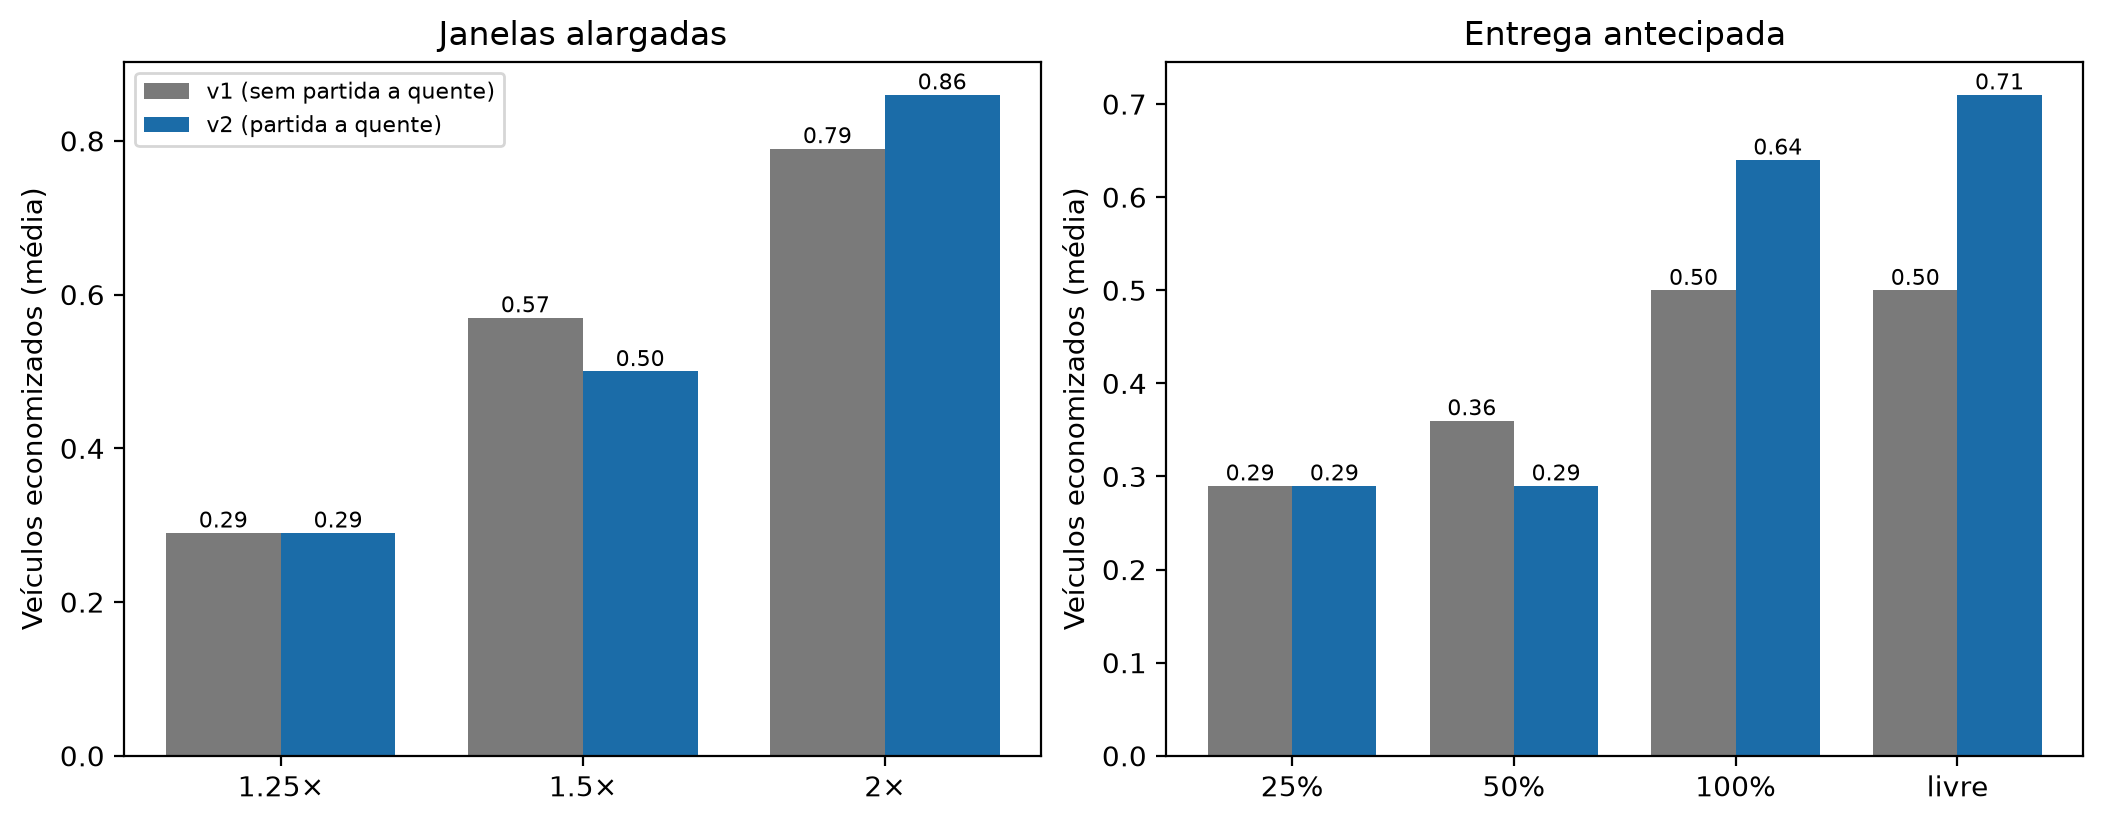

In [7]:
window_v2 = results.load_window_scenarios(R["v2_B5_windows"], split)
early_v2 = results.load_early_delivery(R["v2_B5_early"], split)

display(eda.localize_columns(v2_view.layerb_warm_counts(window_v2, early_v2, LANG), LANG))
display(eda.localize_columns(v2_view.layerb_nonmonotonic(window, window_v2, early, early_v2, LANG), LANG))
display(eda.localize_columns(v2_view.layerb_levels(window, window_v2, early, early_v2, LANG, include_base=True), LANG))

viz_business.plot_warm_start(v2_view.layerb_levels(window, window_v2, early, early_v2, LANG), LANG)
plt.show()

### Insight

Todas as 56 células de janelas alargadas e as 210 de entrega antecipada mostraram-se factíveis, com 42 e 168 execuções partindo a quente do nível anterior enquanto os níveis iniciais (14 e 42) partiram a frio. Com a partida a quente, todas as células não monotônicas desapareceram, caindo de 6 para 0 em janelas alargadas e de 14 para 0 em entrega antecipada, confirmando que os desvios da seção 6 decorriam da busca independente a frio e não da estrutura do problema.

Os veículos economizados frente ao plano-base de cada versão variaram discretamente sem direção única (por exemplo, em janelas ×2 foram 0,79 na v1 contra 0,86 na v2, e em antecipação livre foram 0,50 contra 0,71), refletindo diferenças pontuais de partida no nível base em rodada de 30 s dentro do ruído esperado de 1 veículo. Apesar de B5 sanar a monotonicidade, as seções principais mantêm a v1 como referência original do experimento.

## 8. Síntese para o negócio

Os ganhos com a flexibilização de janelas concentram-se exclusivamente nas famílias R e RC, em que restrições horárias determinam a frota. Alargar janelas por fator 2 economizou em média 0,79 veículo (reduzindo a frota em 8 de 14 instâncias, com −12,3% de distância onde houve redução e −2,0% onde a frota ficou igual), enquanto a entrega antecipada livre poupou 0,50 veículo em média (com reduções de −18,1% na distância e −20,8% na duração ótima nos casos de frota igual, chegando a −36,7% em R2 e −34,8% em RC2, e de −11,0% e −11,7% onde houve corte de frota). Já nas famílias C, governadas pela capacidade dos veículos, nenhuma flexibilidade horária reduziu a frota nem trouxe ganho expressivo de duração (entre −0,9% e +0,0%).

Qualquer interpretação exige cautela quanto ao critério de medição e ao custo operacional de troca. Distâncias e durações só são comparáveis dentro da mesma classe de frota, e medições ingênuas com partida simultânea no instante zero superestimam a economia de duração em 1,0 a 7,9 pontos percentuais frente à saída ótima, além de a duração ser efeito secundário da minimização de frota e distância. Na operação, mesmo 25% de antecipação reorganiza cerca de 40% dos clientes e preserva menos de 40% dos arcos originais, impondo um custo de adaptação de rotas e motoristas que precisa superar a economia obtida. Por fim, embora o experimento B5 tenha zerado os 20 casos não monotônicos da v1 mediante partida a quente sem alterar essas conclusões qualitativas, os resultados restringem-se a 14 instâncias sintéticas sem comparação com o SINTEF nem modelagem explícita de aceitação dos clientes.

## Referências

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., & Stewart, W. R. (1995). Designing and reporting on computational experiments with heuristic methods. *Journal of Heuristics, 1*(1), 9–32.
- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- Rand, W. M. (1971). Objective criteria for the evaluation of clustering methods. *Journal of the American Statistical Association, 66*(336), 846–850.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: Minimizing route duration. *ORSA Journal on Computing, 4*(2), 146–154.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.